# Análisis de ventas de e-commerce

**Python · Pandas · Matplotlib · Power BI**  
**Período analizado:** enero a junio de 2026 · **1.000 órdenes**

Quise analizar las ventas de un e-commerce para responder preguntas comerciales: qué productos y categorías generan más ingresos, cómo cambian las ventas de un mes a otro y qué ciudades aportan más facturación.

Primero revisé la calidad del dataset, después preparé los indicadores y finalmente comparé productos, categorías, meses y ciudades. Los gráficos de Power BI complementan estos resultados.

> Es un proyecto de práctica con datos de e-commerce, no un trabajo realizado para una empresa real. El dataset no identifica la moneda, así que los importes se presentan como unidades monetarias.

## 1. Carga y revisión inicial

Empecé mirando la estructura del archivo. Antes de calcular ingresos, quería confirmar cuántos registros tenía, si había datos faltantes y si podía usar `Order_ID` para contar órdenes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Colocar el CSV original en la misma carpeta que este notebook.
df = pd.read_csv("ecommerce_sales_1000_records.csv")
df.head()

,Order_ID,Product,Category,Quantity,Price,City,Date
0,ORD1001,Backpack,Accessories,1,1629.00,Hyderabad,2026-03-04
1,ORD1002,Keyboard,Electronics,2,1570.94,Surat,2026-01-23
2,ORD1003,Book,Books,4,407.86,Mumbai,2026-02-25
3,ORD1004,Keyboard,Electronics,5,1530.61,Surat,2026-02-20
4,ORD1005,Tablet,Electronics,5,27549.31,Jaipur,2026-05-31


In [2]:
print(f"Filas y columnas: {df.shape}")
print("\nTipos de datos:")
df.info()
print("\nValores faltantes por columna:")
print(df.isna().sum())
print(f"\nFilas duplicadas: {df.duplicated().sum()}")
print(f"Order_ID repetidos: {df['Order_ID'].duplicated().sum()}")

Filas y columnas: (1000, 7)

Tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  1000 non-null   object 
 1   Product   1000 non-null   object 
 2   Category  1000 non-null   object 
 3   Quantity  1000 non-null   int64  
 4   Price     1000 non-null   float64
 5   City      1000 non-null   object 
 6   Date      1000 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 54.8+ KB

Valores faltantes por columna:
Order_ID    0
Product     0
Category    0
Quantity    0
Price       0
City        0
Date        0
dtype: int64

Filas duplicadas: 0
Order_ID repetidos: 0


In [3]:
print("Productos distintos:", df["Product"].nunique())
print("Categorías distintas:", df["Category"].nunique())
print("Ciudades distintas:", df["City"].nunique())

# Compruebo si un mismo producto aparece asociado a más de una categoría.
product_category_check = df.groupby("Product")["Category"].nunique()
print("Productos con más de una categoría:", (product_category_check > 1).sum())

# También verifico que cantidad y precio sean positivos.
print("Filas con Quantity o Price no positivos:", ((df["Quantity"] <= 0) | (df["Price"] <= 0)).sum())

Productos distintos: 14
Categorías distintas: 5
Ciudades distintas: 10
Productos con más de una categoría: 0
Filas con Quantity o Price no positivos: 0


Encontré **1.000 registros y 7 columnas**, sin valores faltantes, sin filas duplicadas y sin `Order_ID` repetidos. El dataset tiene **14 productos, 5 categorías y 10 ciudades**. También comprobé que los productos mantuvieran su categoría y que cantidades y precios fueran positivos.

La estructura estaba bastante limpia. Lo que sí necesitaba era convertir `Date`, que se había leído como texto, para poder analizar los meses correctamente.

## 2. Fechas y preparación de los datos

Convertí la fecha y revisé el período real del archivo. Después calculé la facturación de cada orden multiplicando cantidad por precio.

In [4]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Fechas no válidas:", df["Date"].isna().sum())
print("Primera fecha:", df["Date"].min().date())
print("Última fecha:", df["Date"].max().date())

Fechas no válidas: 0
Primera fecha: 2026-01-01
Última fecha: 2026-06-29


In [5]:
df["Revenue"] = df["Quantity"] * df["Price"]
df["Month"] = df["Date"].dt.to_period("M")

print("Facturaciones no positivas:", (df["Revenue"] <= 0).sum())
df[["Order_ID", "Product", "Quantity", "Price", "Revenue", "Date", "Month"]].head()

Facturaciones no positivas: 0


,Order_ID,Product,Quantity,Price,Revenue,Date,Month
0,ORD1001,Backpack,1,1629.00,1629.00,2026-03-04,2026-03
1,ORD1002,Keyboard,2,1570.94,3141.88,2026-01-23,2026-01
2,ORD1003,Book,4,407.86,1631.44,2026-02-25,2026-02
3,ORD1004,Keyboard,5,1530.61,7653.05,2026-02-20,2026-02
4,ORD1005,Tablet,5,27549.31,137746.55,2026-05-31,2026-05


El período va del **1 de enero al 29 de junio de 2026**. No aparecieron fechas inválidas ni facturaciones nulas o negativas.

Usé `Revenue = Quantity × Price` como medida de facturación. El archivo no tiene costos, devoluciones ni descuentos, por lo que **facturación no equivale a ganancia**.

## 3. Indicadores generales

Antes de comparar grupos, calculé cuatro indicadores para tener una referencia del tamaño del conjunto de ventas.

In [6]:
total_revenue = df["Revenue"].sum()
total_orders = df["Order_ID"].nunique()
total_units = df["Quantity"].sum()
avg_order_value = total_revenue / total_orders

kpis = pd.Series({
    "Facturación total": total_revenue,
    "Órdenes": total_orders,
    "Unidades vendidas": total_units,
    "Ticket promedio": avg_order_value,
})
kpis.round(2)

Facturación total    27620651.09
Órdenes                  1000.00
Unidades vendidas        3035.00
Ticket promedio         27620.65
dtype: float64

La facturación total es de aproximadamente **27,62 millones de unidades monetarias**, con **1.000 órdenes** y **3.035 unidades vendidas**. El ticket promedio es de **27.620,65 por orden**. Son los cuatro indicadores principales que utilicé en Power BI.

## 4. Productos: facturación y unidades

Primero ordené los productos por ingresos y luego por unidades. Quería comprobar si los artículos que más se venden son también los que más facturan.

In [7]:
product_summary = (
    df.groupby("Product")
    .agg(
        total_revenue=("Revenue", "sum"),
        total_quantity=("Quantity", "sum"),
        avg_price=("Price", "mean"),
        orders=("Order_ID", "nunique"),
    )
    .sort_values("total_revenue", ascending=False)
)
product_summary["revenue_pct"] = product_summary["total_revenue"] / total_revenue * 100
product_summary["revenue_pct_cumulative"] = product_summary["revenue_pct"].cumsum()
product_summary.round(2)

,total_revenue,total_quantity,avg_price,orders,revenue_pct,revenue_pct_cumulative
Product,,,,,,
Laptop,11411335.18,207,55237.98,65,41.31,41.31
Tablet,5933914.09,215,27555.18,69,21.48,62.80
Smartphone,3535262.79,199,17853.84,68,12.80,75.60
Air Fryer,1533421.53,239,6440.47,78,5.55,81.15
Watch,1203724.83,241,5000.51,79,4.36,85.51
Coffee Maker,812719.87,193,4218.20,64,2.94,88.45
Mixer,795340.32,226,3534.57,77,2.88,91.33
Shoes,515253.55,206,2507.79,73,1.87,93.19
Jeans,428059.92,214,1993.43,69,1.55,94.74


In [8]:
product_summary.sort_values("total_quantity", ascending=False)[
    ["total_quantity", "total_revenue", "avg_price", "orders"]
].head(10).round(2)

,total_quantity,total_revenue,avg_price,orders
Product,,,,
T-Shirt,259,209054.91,809.95,84
Watch,241,1203724.83,5000.51,79
Backpack,241,426721.67,1780.64,82
Air Fryer,239,1533421.53,6440.47,78
Mixer,226,795340.32,3534.57,77
Keyboard,218,329956.17,1510.96,69
Tablet,215,5933914.09,27555.18,69
Jeans,214,428059.92,1993.43,69
Laptop,207,11411335.18,55237.98,65


**Laptop** es el producto que más factura, con aproximadamente **11,41 millones**, aunque no es el que más unidades vende. **T-Shirt** lidera por cantidad con **259 unidades**, mientras que Laptop suma **207**.

Esto me mostró que mirar solo las unidades no alcanza para entender el peso comercial de cada producto. Además, **Laptop, Tablet y Smartphone** explican juntos alrededor del **75,60 %** de toda la facturación; el negocio está muy concentrado en esos tres productos.

## 5. Categorías

Después agrupé los registros por categoría para comparar facturación, órdenes, unidades y precio promedio. La idea era entender si esa concentración también se veía a un nivel más general.

In [9]:
category_summary = (
    df.groupby("Category")
    .agg(
        total_revenue=("Revenue", "sum"),
        total_quantity=("Quantity", "sum"),
        orders=("Order_ID", "nunique"),
        avg_order_value=("Revenue", "mean"),
        avg_price=("Price", "mean"),
    )
    .sort_values("total_revenue", ascending=False)
)
category_summary["revenue_pct"] = category_summary["total_revenue"] / total_revenue * 100
category_summary.round(2)

,total_revenue,total_quantity,orders,avg_order_value,avg_price,revenue_pct
Category,,,,,,
Electronics,21606517.72,1017,328,65873.53,21147.59,78.23
Home Appliances,3141481.72,658,219,14344.67,4769.33,11.37
Accessories,1630446.50,482,161,10127.00,3360.57,5.90
Fashion,1152368.38,679,226,5098.98,1719.70,4.17
Books,89836.77,199,66,1361.16,452.86,0.33


**Electronics** concentra el **78,23 % de la facturación**, unos **21,61 millones**. Es una fortaleza comercial, pero también una concentración que convendría vigilar. En el otro extremo, **Books** representa apenas el **0,33 %**.

Esto no significa automáticamente que haya que dejar de vender libros ni aumentar inventario de electrónica: para decidirlo necesitaría conocer márgenes, costos, existencias y demanda.

## 6. Ventas por ciudad

Quise comparar la facturación geográfica sin quedarme solamente con la ciudad que aparece más veces en el archivo.

In [10]:
city_summary = (
    df.groupby("City")
    .agg(
        total_revenue=("Revenue", "sum"),
        total_quantity=("Quantity", "sum"),
        orders=("Order_ID", "nunique"),
        avg_order_value=("Revenue", "mean"),
    )
    .sort_values("total_revenue", ascending=False)
)
city_summary["revenue_pct"] = city_summary["total_revenue"] / total_revenue * 100
city_summary.round(2)

,total_revenue,total_quantity,orders,avg_order_value,revenue_pct
City,,,,,
Pune,3262077.43,307,102,31981.15,11.81
Mumbai,3213056.46,378,126,25500.45,11.63
Jaipur,3161091.50,312,105,30105.63,11.44
Bangalore,3148292.69,270,88,35776.05,11.40
Kolkata,2971339.46,267,87,34153.33,10.76
Surat,2798244.03,334,105,26649.94,10.13
Delhi,2660336.42,281,94,28301.45,9.63
Chennai,2359385.36,308,98,24075.36,8.54
Ahmedabad,2127277.96,302,99,21487.66,7.70


**Pune** es la ciudad con mayor facturación, aproximadamente **3,26 millones** y **11,81 %** del total. **Mumbai**, en cambio, es la que tiene más órdenes (**126**), pero queda segunda en ingresos.

La facturación entre ciudades está más repartida que entre categorías y productos. Eso me pareció interesante: una ciudad puede liderar en cantidad de operaciones y otra en valor facturado.

## 7. Evolución y variación mensual

Por último, preparé un resumen mensual con ingresos, unidades, cantidad de órdenes y ticket promedio. Después calculé las variaciones porcentuales respecto al mes anterior.

In [11]:
monthly_summary = (
    df.groupby("Month")
    .agg(
        total_revenue=("Revenue", "sum"),
        total_quantity=("Quantity", "sum"),
        orders=("Order_ID", "nunique"),
        avg_order_value=("Revenue", "mean"),
    )
    .sort_index()
)
for col in ["total_revenue", "total_quantity", "orders", "avg_order_value"]:
    monthly_summary[f"{col}_change_pct"] = monthly_summary[col].pct_change() * 100
monthly_summary.round(2)

,total_revenue,total_quantity,orders,avg_order_value,total_revenue_change_pct,total_quantity_change_pct,orders_change_pct,avg_order_value_change_pct
Month,,,,,,,,
2026-01,5205216.14,521,170,30618.92,NaN,NaN,NaN,NaN
2026-02,4418598.64,462,151,29262.24,-15.11,-11.32,-11.18,-4.43
2026-03,4668486.25,532,181,25792.74,5.66,15.15,19.87,-11.86
2026-04,4655427.19,511,164,28386.75,-0.28,-3.95,-9.39,10.06
2026-05,4860089.35,522,184,26413.53,4.40,2.15,12.20,-6.95
2026-06,3812833.52,487,150,25418.89,-21.55,-6.70,-18.48,-3.77


**Enero** tuvo la mayor facturación (**5,21 millones**), pero **marzo** fue el mes con más unidades (**532**) y **mayo** el de más órdenes (**184**). Una vez más, cantidad y facturación no cuentan necesariamente lo mismo.

**Junio** fue el mes de menor facturación (**3,81 millones**) y cayó **21,55 % respecto de mayo**. Pasó de 184 a 150 órdenes y también se redujo el ticket promedio. Los datos muestran qué cambió, pero no explican por sí solos las causas: para investigarlas necesitaría información de campañas, precios, estacionalidad y otros factores.

## 8. Gráficos para revisar los resultados

Generé algunas visualizaciones rápidas en Python para comprobar los patrones principales. El dashboard final lo construí en Power BI, con filtros por mes, categoría, ciudad y producto.

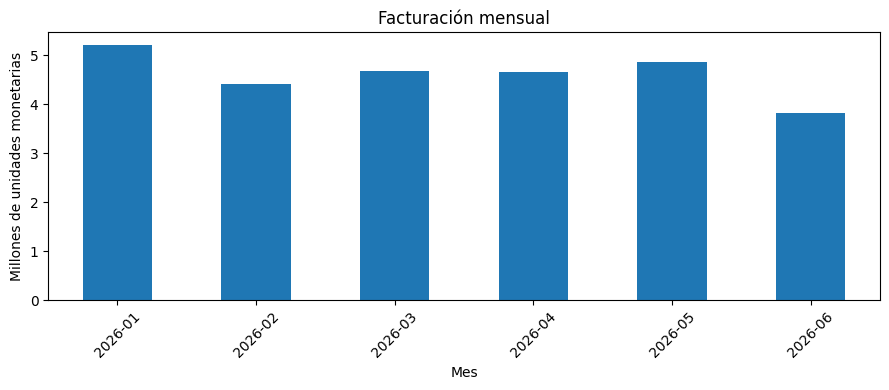

In [12]:
(monthly_summary["total_revenue"] / 1_000_000).rename_axis("Mes").plot(
    kind="bar", title="Facturación mensual", figsize=(9, 4)
)
plt.ylabel("Millones de unidades monetarias")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

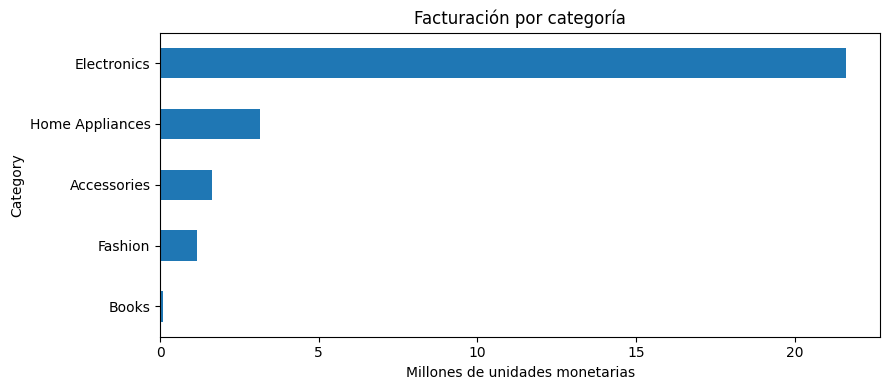

In [13]:
(category_summary["total_revenue"] / 1_000_000).sort_values().plot(
    kind="barh", title="Facturación por categoría", figsize=(9, 4)
)
plt.xlabel("Millones de unidades monetarias")
plt.tight_layout()
plt.show()

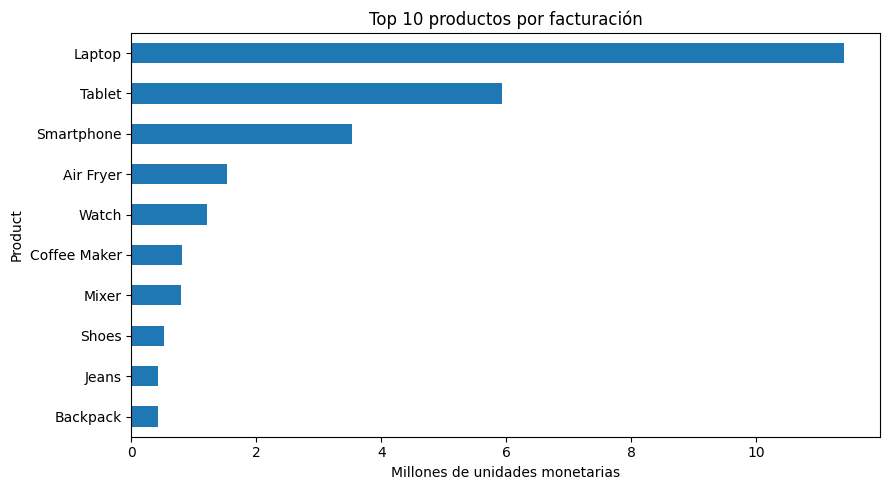

In [14]:
(product_summary["total_revenue"].head(10) / 1_000_000).sort_values().plot(
    kind="barh", title="Top 10 productos por facturación", figsize=(9, 5)
)
plt.xlabel("Millones de unidades monetarias")
plt.tight_layout()
plt.show()

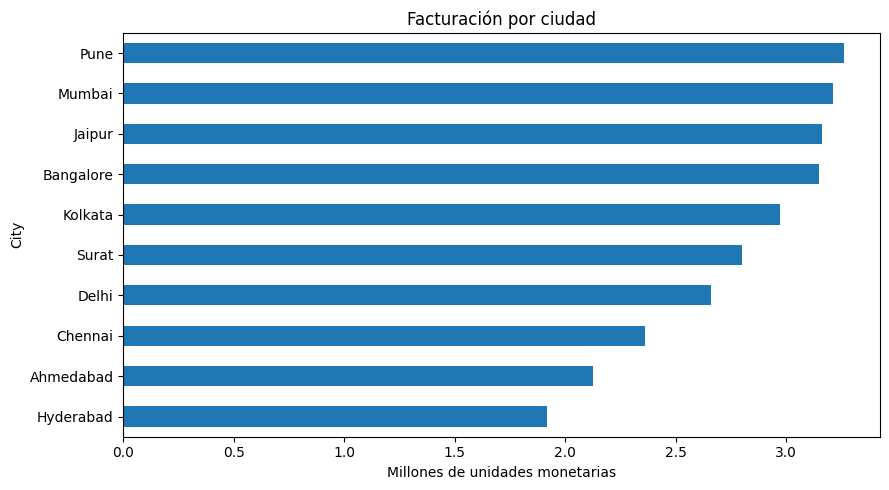

In [15]:
(city_summary["total_revenue"] / 1_000_000).sort_values().plot(
    kind="barh", title="Facturación por ciudad", figsize=(9, 5)
)
plt.xlabel("Millones de unidades monetarias")
plt.tight_layout()
plt.show()

## 9. Hallazgos y acciones que evaluaría

- **Concentración:** Electronics aporta 78,23 % y tres productos explican cerca de 75,60 % de la facturación. Revisaría esa dependencia antes de definir campañas o compras.
- **Volumen frente a ingresos:** T-Shirt vende más unidades que Laptop, pero genera mucho menos ingreso. Para decidir promociones, miraría tanto unidades como facturación, y sumaría el margen de cada producto.
- **Caída de junio:** la facturación baja 21,55 % frente a mayo. Investigaría órdenes, ticket promedio y mezcla de productos, pero no atribuiría la caída a una causa sin más datos.
- **Ciudades:** la facturación está relativamente repartida. Evaluaría oportunidades por ubicación según ticket y comportamiento de compra, antes de definir una campaña.

**Limitaciones:** el dataset tiene seis meses de ventas y no incluye costos, margen, stock, devoluciones ni información de campañas. Por eso las recomendaciones son hipótesis comerciales para investigar, no decisiones definitivas.

## 10. Exportación para Power BI

Para llevar los resultados al dashboard, exporté los datos preparados y las tablas de resumen a un Excel con varias hojas. El archivo se genera al ejecutar esta celda y no hace falta versionarlo en GitHub.

In [16]:
with pd.ExcelWriter("ecommerce_analytics_outputs.xlsx") as writer:
    df.to_excel(writer, sheet_name="clean_data", index=False)
    product_summary.to_excel(writer, sheet_name="product_summary")
    category_summary.to_excel(writer, sheet_name="category_summary")
    city_summary.to_excel(writer, sheet_name="city_summary")
    monthly_summary.to_excel(writer, sheet_name="monthly_summary")

print("Archivo generado: ecommerce_analytics_outputs.xlsx")

Archivo generado: ecommerce_analytics_outputs.xlsx
